# # Plotting with [nspl](https://pityka.github.io/nspl)
#
# [nspl](https://github.com/pityka/nspl) is a 2D plotting library for Scala 2.13 and Scala 3, on the JVM and with Scala.js.
# It describes plots as immutable values, that a renderer turns into images. On the JVM, the `nspl-awt` module renders them
# to bitmaps (PNG, JPEG) or vector formats (SVG, PDF, EPS), that we can show in the notebook with almond's `Image` and `Svg` displays.

In [1]:
//> using dep io.github.pityka::nspl-awt:0.20.0

import org.nspl._
import org.nspl.awtrenderer._

// Renders a plot as a PNG image in the notebook
def showPng[K <: Renderable[K]](plot: Build[K], width: Int = 800)(implicit renderer: Renderer[K, JavaRC]) =
  Image(renderToByteArray(plot, width = width)).withFormat(Image.PNG)

// Renders a plot as an SVG image in the notebook
def showSvg[K <: Renderable[K]](plot: Build[K], width: Int = 600)(implicit renderer: Renderer[K, JavaRC]) =
  Svg(new String(renderToByteArray(plot, width = width, mimeType = "image/svg"), "UTF-8"))

import org.nspl._
import org.nspl.awtrenderer._
defined function showPng
defined function showSvg

# ## Scatter plots
#
# `xyplot` is the main entry point of nspl. Its first parameter list takes data sources, each optionally with
# data renderers (points, lines, bars, …) and a legend entry. Its second parameter list takes the plot parameters,
# with `par` holding the default ones.

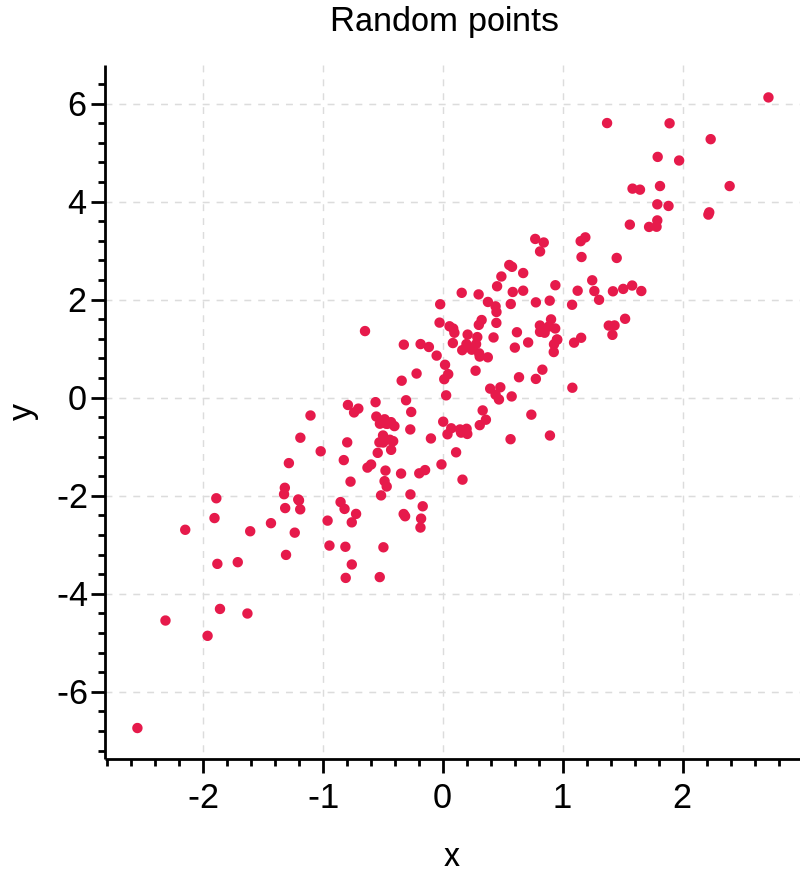

rng: scala.util.Random = scala.util.Random@11cb65e2
points: Seq[(Double, Double)] = List(
  (1.1419053154730547, 3.2032185799288975),
  (-0.9498666368908959, -3.0067235601811295),
  (0.2809776380727795, 1.2465780717782144),
  (-0.8172214073987268, -3.0310862174754973),
  (-0.19094451307087512, 1.1043243662489),
  (0.8023071496873626, 1.4831013747092319),
  (1.4105062239438624, 2.1807796656741507),
  (-1.2096444592532913, -2.0655312206345537),
  (-0.4903496491990076, -0.4299777601236523),
  (-1.2035510019650835, -2.0860859232885254),
  (1.5511476388671834, 3.540825563981472),
  (0.4815980608245389, 2.482827200617146),
  (-0.2768317291873249, -0.6376024368695132),
  (1.255833005788796, 2.186393217711015),
  (-0.17329033306108363, -2.20516581070862),
  (1.4238069456328435, 1.483887867190664),
  (-1.964666098753878, -4.847927041441945),
  (-2.548887393384806, -6.728735444611543),
  (-0.12200477461989162, 1.0451495225617937),
  (-0.2691388556559934, -0.28078630280289785),
  (-0.319914376004

In [2]:
val rng = new scala.util.Random(42)

val points = Seq.fill(200) {
  val x = rng.nextGaussian()
  x -> (2 * x + rng.nextGaussian())
}

showPng(
  xyplot(points)(
    par.withMain("Random points").withXLab("x").withYLab("y")
  )
)

# A third column of the data can give the color of the points. Here, we color the points by cluster:

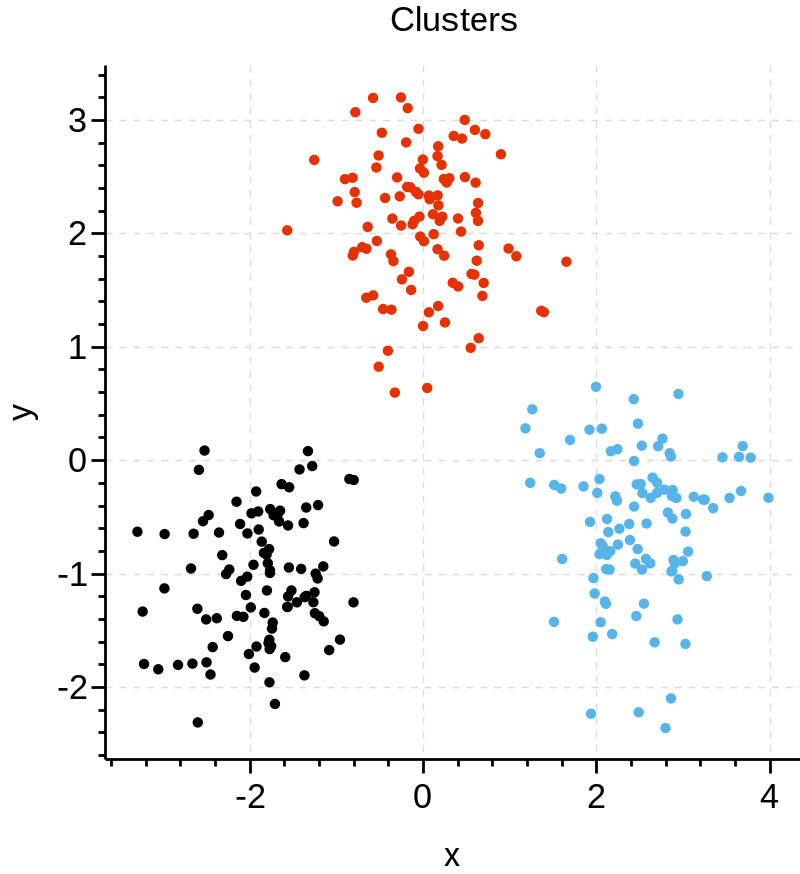

centers: Seq[(Double, Double)] = List((-2.0, -1.0), (0.0, 2.0), (2.5, -0.5))
clustered: Seq[(Double, Double, Double)] = List(
  (-1.4113984660159602, -0.9542710642468756, 0.0),
  (-3.300134891296195, -0.6268064457640053, 0.0),
  (-2.2405324291306328, -0.9598967379890918, 0.0),
  (-2.831368799508478, -1.8007605123223986, 0.0),
  (-2.6821592531060148, -0.9506369058172918, 0.0),
  (-1.5947602266981373, -1.7322880546843735, 0.0),
  (-1.7813839454759646, -0.7799220856293014, 0.0),
  (-1.747850313363298, -1.480589703021379, 0.0),
  (-1.771120543526679, -0.9905890768993088, 0.0),
  (-1.9071351595124688, -0.4481516657131257, 0.0),
  (-1.2162045175392282, -0.3920010603061366, 0.0),
  (-1.9265673374737866, -1.6388899756182231, 0.0),
  (-1.5234278979313896, -1.1447577890294576, 0.0),
  (-2.0780636461569646, -1.3769772884230855, 0.0),
  (-1.7881188408170752, -1.6078515977015637, 0.0),
  (-2.4783712276029473, -0.4797929979022032, 0.0),
  (-2.502915952336091, -1.7784791887223879, 0.0),
  (-1.3835068

In [3]:
val centers = Seq((-2.0, -1.0), (0.0, 2.0), (2.5, -0.5))

val clustered = for {
  (center, cluster) <- centers.zipWithIndex
  _ <- 1 to 100
} yield (center._1 + rng.nextGaussian() * 0.6, center._2 + rng.nextGaussian() * 0.6, cluster.toDouble)

showPng(
  xyplot(clustered -> point(color = DiscreteColors(centers.length)))(
    par.withMain("Clusters").withXLab("x").withYLab("y")
  )
)

# ## Line plots
#
# Pass `line()` as data renderer to draw lines between the points, and `InLegend` to add a series to the legend:

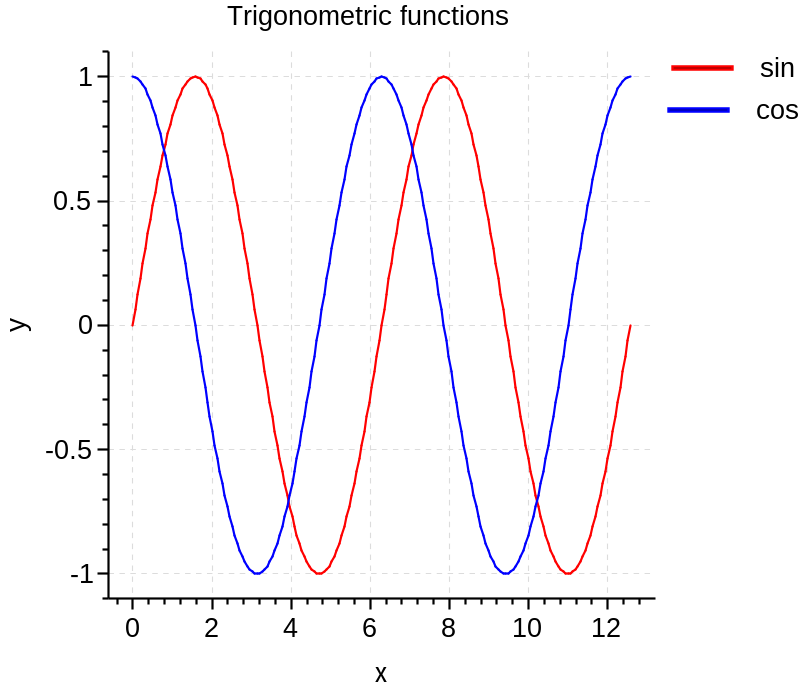

xs: IndexedSeq[Double] = Vector(
  0.0,
  0.06283185307179587,
  0.12566370614359174,
  0.18849555921538758,
  0.25132741228718347,
  0.3141592653589793,
  0.37699111843077515,
  0.43982297150257105,
  0.5026548245743669,
  0.5654866776461628,
  0.6283185307179586,
  0.6911503837897545,
  0.7539822368615503,
  0.8168140899333463,
  0.8796459430051421,
  0.9424777960769378,
  1.0053096491487339,
  1.0681415022205298,
  1.1309733552923256,
  1.1938052083641213,
  1.2566370614359172,
  1.3194689145077132,
  1.382300767579509,
  1.4451326206513047,
  1.5079644737231006,
  1.5707963267948966,
  1.6336281798666925,
  1.6964600329384882,
  1.7592918860102842,
  1.8221237390820801,
  1.8849555921538756,
  1.9477874452256716,
  2.0106192982974678,
  2.0734511513692637,
  2.1362830044410597,
  2.199114857512855,
  2.261946710584651,
  2.324778563656447,
...

In [4]:
val xs = (0 to 200).map(_ * math.Pi / 50)

showPng(
  xyplot(
    (xs.map(x => x -> math.sin(x)), List(line(color = Color.red)), InLegend("sin")),
    (xs.map(x => x -> math.cos(x)), List(line(color = Color.blue)), InLegend("cos"))
  )(
    par.withMain("Trigonometric functions").withXLab("x").withYLab("y")
  )
)

# ## Distributions
#
# Box plots summarize the distribution of values per group:

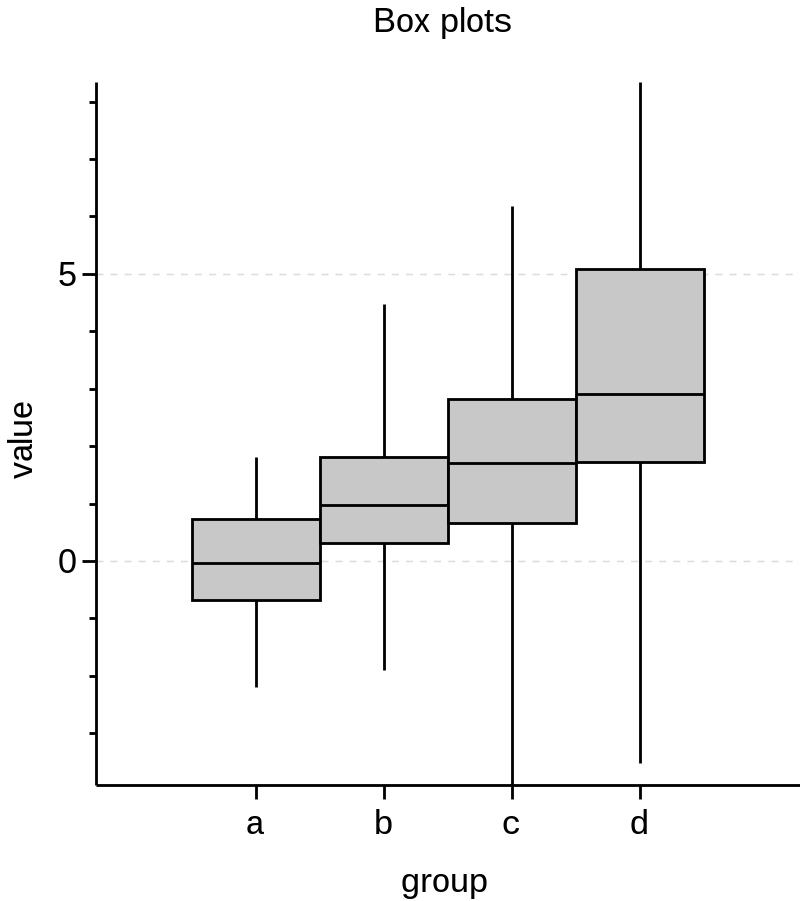

measurements: Seq[(String, Double)] = List(
  ("a", -1.70471754448335),
  ("a", -0.603039803403039),
  ("a", 1.8076920787881408),
  ("a", 0.04866804796093111),
  ("a", -0.8727911962477224),
  ("a", -0.5352277447759726),
  ("a", 0.040051801737782715),
  ("a", 0.724354900707523),
  ("a", -0.48277651755236467),
  ("a", -0.2992663572658701),
  ("a", -1.0489017622871448),
  ("a", 0.18362320101561097),
  ("a", -0.683201622274308),
  ("a", 1.4428039429796768),
  ("a", 1.4756139520462779),
  ("a", 0.31687464091774803),
  ("a", 1.132666860963296),
  ("a", -2.1984022921949467),
  ("a", 0.6326265827096552),
  ("a", -0.8645031549685142),
  ("a", 0.5327303449013862),
  ("a", 0.8862673099243719),
  ("a", -0.15660464980010244),
  ("a", -0.038265078414060294),
  ("a", -0.036782173354143605),
  ("a", 0.7656392455188015),
  ("a", -0.3833611858131972),
  ("a", -0.6332627617733155),
  ("a", 0.6148100615636093),
  ("a", 0.9120508667715109),
  ("a", 0.8531415713908175),
  ("a", 0.9856258806463459),
  ("a", 

In [5]:
val measurements = for {
  group <- Seq("a", "b", "c", "d")
  shift = group.head - 'a'
  _ <- 1 to 50
} yield group -> (shift + rng.nextGaussian() * (1 + shift / 2.0))

showPng(
  boxplotFromLabels(measurements)(
    par.withMain("Box plots").withXLab("group").withYLab("value")
  )
)

# while dot plots show all of them, spread horizontally according to their density (`bandwidth` controls the smoothing):

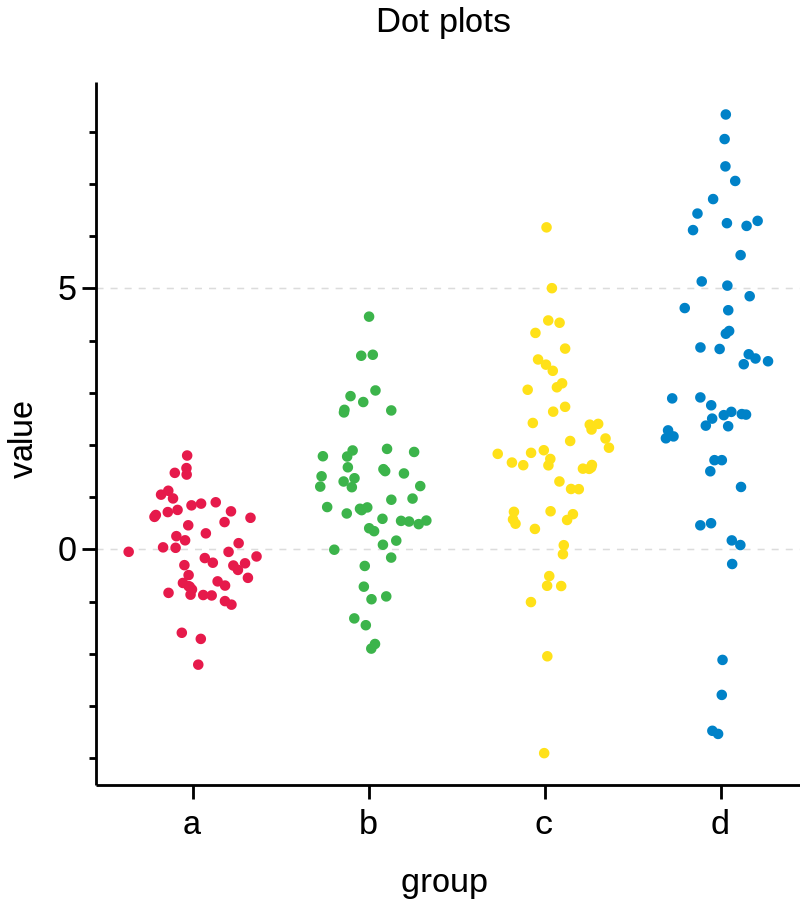

In [6]:
showPng(
  dotplotFromLabels(measurements, bandwidth = 0.5)(
    par.withMain("Dot plots").withXLab("group").withYLab("value")
  )
)

# ## Combining plots
#
# `sequence` lays out several plots, here in a table with two columns:

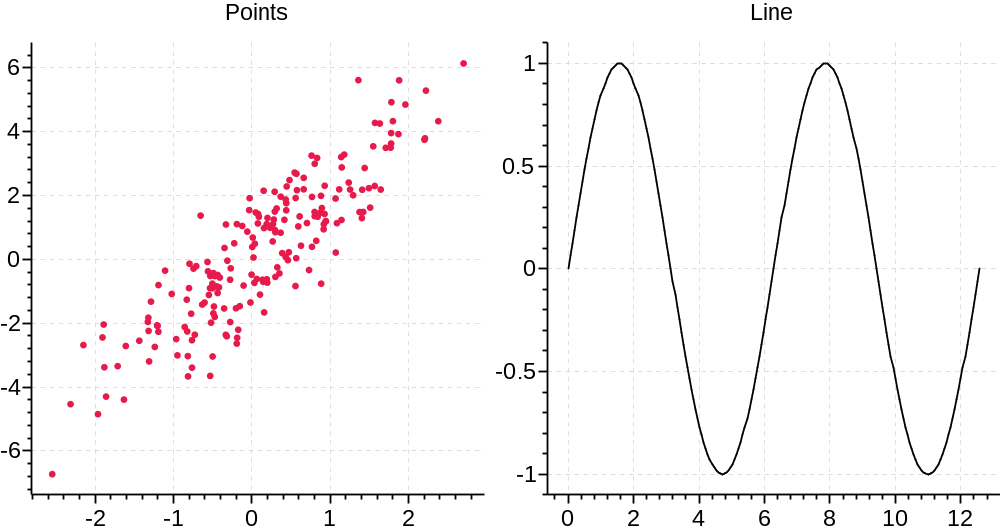

In [7]:
showPng(
  sequence(
    List(
      xyplot(points)(par.withMain("Points")),
      xyplot(xs.map(x => x -> math.sin(x)) -> line())(par.withMain("Line"))
    ),
    TableLayout(2)
  ),
  width = 1000
)

# ## Vector output
#
# The same plots can be rendered as SVG, that stays sharp when zoomed in:

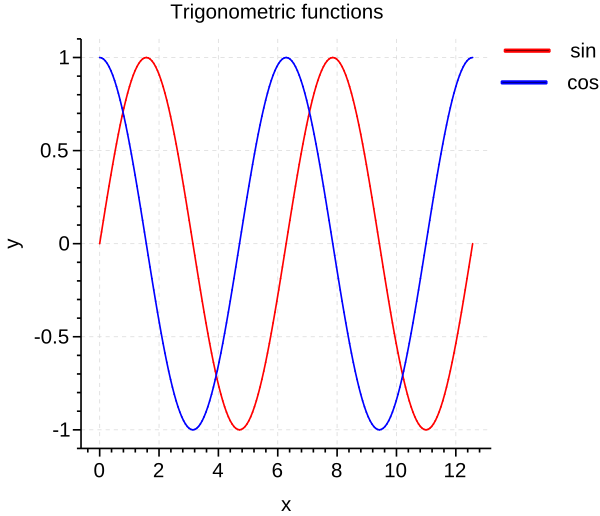

In [8]:
showSvg(
  xyplot(
    (xs.map(x => x -> math.sin(x)), List(line(color = Color.red)), InLegend("sin")),
    (xs.map(x => x -> math.cos(x)), List(line(color = Color.blue)), InLegend("cos"))
  )(
    par.withMain("Trigonometric functions").withXLab("x").withYLab("y")
  )
)

# `renderToByteArray(plot, mimeType = "application/pdf")` renders plots as PDF, and `renderToFile` writes them to a file.
# See the [nspl documentation](https://pityka.github.io/nspl) for more plot types (contour plots, raster plots, density plots, 3D scatter plots…)
# and for the many parameters plots accept.